# MIAS, Notebook 1: data, preprocessing, ground truth and cross-validation folds

In [ ]:
# Imports and config
!pip install -q opencv-python scikit-learn tqdm kaggle

import os, json, random, warnings, math, time, glob, shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import StratifiedGroupKFold
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/mias_grc_project_v3_cv"      
N_FOLDS = 5                                                      
VAL_SHARE_INNER = 0.25                                            

CONFIG = {
    "SEED": 42, "DRIVE_ROOT": DRIVE_ROOT, "DATASET_DIR": "/content/mias_dataset",
    "TARGET_CLASSES": ["CIRC", "SPIC", "MISC"], "EXPECTED_TOTAL": 322,
    "CLAHE_CLIP_LIMIT": 2.0, "CLAHE_TILE_FINE": [8, 8], "CLAHE_TILE_COARSE": [16, 16],
    "ROI_MARGIN_FACTOR": 0.3, "ROI_MARGIN_MIN_PX": 20, "ROI_MAX_RADIUS": 150,
    "TRIMAP_ERODE_ITERS": 6, "TRIMAP_DILATE_ITERS": 10,               # same seed rule as the CBIS-DDSM series
    "LAMBDA_VAL": 5.0, "PATCH_SIZES": [3, 5, 7], "PATCH_SINGLE": 5, "HISTOGRAM_WINDOW": 7,
    "SVM_C_VALUES": [0.1, 1, 10], "SVM_GAMMA_VALUES": ["scale", "auto"],
    "HYBRID_GAMMA": 0.9, "MAX_NODES": 2500, "LAMBDA_PROPAGATION": 100.0, "ALPHA_THRESHOLD": 0.5, "HD95_PERCENTILE": 95,
    "N_FOLDS": N_FOLDS, "VAL_SHARE_INNER": VAL_SHARE_INNER,
    "DATA_SOURCE": "MIAS v1.21 (Kaggle mirror kmader/mias-mammography)",
}
for d in ["outputs", "preprocessed", "trimaps", "alpha_maps", "models", "results", "logs", "figures"]:
    p = os.path.join(DRIVE_ROOT, d); os.makedirs(p, exist_ok=True); CONFIG[d.upper() + "_DIR"] = p
globals().update(CONFIG)
SEED = CONFIG["SEED"]; random.seed(SEED); np.random.seed(SEED)
print(f"Project folder: {DRIVE_ROOT}")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/mias_grc_project_v3_cv


## Data 

In [ ]:
import zipfile
def pgm_paths():
    return [os.path.join(dp, f) for dp, _, fn in os.walk(DATASET_DIR) for f in fn if f.lower().endswith('.pgm')] if os.path.isdir(DATASET_DIR) else []
def have_pgm(): return len(pgm_paths())

if have_pgm() < EXPECTED_TOTAL:
    os.makedirs(DATASET_DIR, exist_ok=True)
    if not any(f.lower().endswith('.zip') for f in os.listdir(DATASET_DIR)) and have_pgm() == 0:
        if not os.path.exists('/root/.kaggle/kaggle.json'):
            from google.colab import files
            print("Upload your kaggle.json when prompted.")
            up = files.upload(); name = list(up.keys())[0]
            os.makedirs('/root/.kaggle', exist_ok=True); os.rename(name, '/root/.kaggle/kaggle.json'); os.chmod('/root/.kaggle/kaggle.json', 0o600)
        !kaggle datasets download -d kmader/mias-mammography -p /content/mias_dataset --unzip
    if have_pgm() < EXPECTED_TOTAL:                       
        for z in [f for f in os.listdir(DATASET_DIR) if f.lower().endswith('.zip')]:
            print("Unpacking", z); zipfile.ZipFile(os.path.join(DATASET_DIR, z)).extractall(DATASET_DIR)
print("PGM files present (whole folder tree):", have_pgm())
assert have_pgm() >= EXPECTED_TOTAL, "fewer PGM files than expected; upload the MIAS archive manually to DATASET_DIR"

def find_file(root, part):
    for dp, _, fn in os.walk(root):
        for f in fn:
            if part.lower() in f.lower(): return os.path.join(dp, f)
INFO_PATH = find_file(DATASET_DIR, "Info.txt") or find_file(DATASET_DIR, "info")
from collections import Counter
IMAGES_DIR = Counter(os.path.dirname(p) for p in pgm_paths()).most_common(1)[0][0]      
print("Info file :", INFO_PATH); print("Images dir:", IMAGES_DIR)
assert INFO_PATH, "Info.txt not found"

Upload your kaggle.json when prompted.


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/kmader/mias-mammography
License(s): other
100% 312M/312M [00:02<00:00, 161MB/s]

PGM files present (whole folder tree): 322
Info file : /content/mias_dataset/Info.txt
Images dir: /content/mias_dataset/all-mias


## Annotations: mass cases, patients

In [ ]:
def parse_info(path):
    rows = []
    for line in open(path):
        p = line.split()
        if len(p) < 3 or not p[0].lower().startswith('mdb'): continue
        rec = {'image_id': p[0].upper(), 'tissue': p[1].upper(), 'class': p[2].upper(), 'severity': p[3].upper() if len(p) > 3 else None,
               'x': None, 'y': None, 'radius': None}
        if len(p) >= 7:
            try: rec['x'], rec['y'], rec['radius'] = float(p[4]), float(p[5]), float(p[6])
            except ValueError: pass
        rows.append(rec)
    return pd.DataFrame(rows)

info_df = parse_info(INFO_PATH)
print(f"Parsed {len(info_df)} annotation rows for {info_df['image_id'].nunique()} images")
print(info_df['class'].value_counts().to_string())

df = info_df[info_df['class'].isin(TARGET_CLASSES)].copy()
bad = df[(df['radius'].isna()) | (df['radius'] <= 0)]
if len(bad): print(f"Dropping {len(bad)} mass rows with missing/zero radius: {bad['image_id'].tolist()}")
df = df[~df.index.isin(bad.index)]
dupes = df[df.duplicated('image_id', keep=False)]['image_id'].unique()
if len(dupes):
    print(f"Images listed twice (two findings), keeping the larger one: {list(dupes)}")
    df = df.sort_values('radius', ascending=False).drop_duplicates('image_id', keep='first')
df = df.sort_values('image_id').reset_index(drop=True)
num = df['image_id'].str.extract(r'(\d+)')[0].astype(int)
df['patient_id'] = ["P%03d" % ((n + 1) // 2) for n in num]          
df['lesion_key'] = df['image_id']
print(f"\nMass working set: {len(df)} images, {df['patient_id'].nunique()} patients")
print(df['class'].value_counts().to_string())
print("images per patient:", df.groupby('patient_id').size().value_counts().to_dict())

Parsed 330 annotation rows for 322 images
class
NORM    207
CALC     30
CIRC     25
SPIC     19
ARCH     19
MISC     15
ASYM     15
Dropping 1 mass rows with missing/zero radius: ['MDB059']
Images listed twice (two findings), keeping the larger one: ['MDB005', 'MDB132', 'MDB144']

Mass working set: 55 images, 53 patients
class
CIRC    22
SPIC    19
MISC    14
images per patient: {1: 51, 2: 2}


In [ ]:
def load_pgm(iid):
    for name in (iid.lower(), iid.upper()):
        for ext in ('.pgm', '.PGM'):
            p = os.path.join(IMAGES_DIR, name + ext)
            if os.path.exists(p): return cv2.imread(p, cv2.IMREAD_GRAYSCALE)
loaded, FAILED = {}, []
for iid in tqdm(df['image_id'], desc="loading"):
    img = load_pgm(iid)
    if img is None: FAILED.append((iid, 'file not found')); continue
    if img.shape != (1024, 1024): FAILED.append((iid, f'shape {img.shape}')); continue
    if img.mean() < 1.0: FAILED.append((iid, 'near-black')); continue
    loaded[iid] = img.astype(np.uint8)
print(f"loaded {len(loaded)} / {len(df)}; failed {len(FAILED)} {FAILED[:5]}")
assert len(loaded) == len(df)

loading: 100%|██████████| 55/55 [00:00<00:00, 286.32it/s]

loaded 55 / 55; failed 0 []


## Preprocessing, ROI and circle ground truth

In [ ]:
def remove_background(img):
    _, th = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(th, 8)
    if n <= 1: return img, np.ones_like(img, bool)
    mask = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return (img * mask).astype(np.uint8), mask
def mask_pectoral(img, breast_mask):
    h, w = img.shape; out = img.copy(); th_, tw_ = int(h * 0.35), int(w * 0.30)
    pts = np.array([[0, 0], [tw_, 0], [0, th_]]) if breast_mask[:, :w // 2].sum() >= breast_mask[:, w // 2:].sum() else np.array([[w, 0], [w - tw_, 0], [w, th_]])
    cv2.fillPoly(out, [pts], 0); return out
def multiscale_clahe(img):
    f = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_FINE)).apply(img)
    c = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_COARSE)).apply(img)
    return ((f.astype(np.float32) + c.astype(np.float32)) / 2.0).astype(np.uint8)
def normalize01(img):
    a = img.astype(np.float32); lo, hi = a.min(), a.max()
    return (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a)

def extract_roi_and_gt(norm_img, row):
    h, w = norm_img.shape; cx, cy, r = float(row['x']), float(row['y']), float(row['radius'])
    cy_img = h - cy                                       
    r_eff = min(r, float(ROI_MAX_RADIUS)); capped = r > ROI_MAX_RADIUS
    margin = max(ROI_MARGIN_MIN_PX, int(r_eff * ROI_MARGIN_FACTOR)); total_r = int(r_eff + margin)
    x1, x2, y1, y2 = int(cx - total_r), int(cx + total_r), int(cy_img - total_r), int(cy_img + total_r)
    x1c, y1c, x2c, y2c = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
    roi = norm_img[y1c:y2c, x1c:x2c]
    if roi.size == 0: return None
    side = 2 * total_r
    if roi.shape != (side, side):
        padded = np.zeros((side, side), np.float32); padded[y1c - y1:y1c - y1 + roi.shape[0], x1c - x1:x1c - x1 + roi.shape[1]] = roi; roi = padded
    ccx, ccy = cx - x1, cy_img - y1                        
    yy, xx = np.mgrid[:side, :side]
    gt = (((xx - ccx) ** 2 + (yy - ccy) ** 2) <= r_eff ** 2).astype(np.uint8) * 255
    return roi.astype(np.float32), gt, total_r, capped, r_eff

ROIS, GTS, meta_rows = {}, {}, []
for _, row in tqdm(df.iterrows(), total=len(df), desc="preprocessing"):
    iid = row['image_id']
    bg, bm = remove_background(loaded[iid]); norm = normalize01(multiscale_clahe(mask_pectoral(bg, bm)))
    out = extract_roi_and_gt(norm, row)
    if out is None: print("empty ROI for", iid); continue
    roi, gt, total_r, capped, r_eff = out
    ROIS[iid], GTS[iid] = roi, gt
    meta_rows.append({'image_id': iid, 'class': row['class'], 'patient_id': row['patient_id'], 'roi_size': roi.shape[0], 'annotated_radius': row['radius'],
                      'used_radius': r_eff, 'radius_capped': capped, 'gt_fraction': float((gt > 0).mean())})
meta = pd.DataFrame(meta_rows)
print(f"Preprocessed {len(ROIS)} / {len(df)} images. ROI side: min {meta['roi_size'].min()}, median {int(meta['roi_size'].median())}, max {meta['roi_size'].max()} px")
print(f"Radius capped on {int(meta['radius_capped'].sum())} image(s): {meta[meta['radius_capped']][['image_id', 'annotated_radius', 'used_radius']].values.tolist()}")
print(f"Annotated radius in px: min {meta['annotated_radius'].min():.0f}, median {meta['annotated_radius'].median():.0f}, max {meta['annotated_radius'].max():.0f}")
assert len(ROIS) == len(df)

preprocessing: 100%|██████████| 55/55 [00:03<00:00, 16.76it/s]

Preprocessed 55 / 55 images. ROI side: min 74, median 134, max 390 px
Radius capped on 2 image(s): [['MDB001', 197.0, 150.0], ['MDB148', 174.0, 150.0]]
Annotated radius in px: min 17, median 47, max 197


## Patient-grouped cross-validation folds

In [6]:
final_df = df[df['image_id'].isin(ROIS)].reset_index(drop=True)
ids = final_df['image_id'].to_numpy(); y = final_df['class'].to_numpy(); g = final_df['patient_id'].to_numpy()
outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = []
for k, (tr_idx, te_idx) in enumerate(outer.split(ids, y, g)):
    inner = StratifiedGroupKFold(n_splits=max(2, int(round(1 / VAL_SHARE_INNER))), shuffle=True, random_state=SEED + k)
    a, b = next(inner.split(ids[tr_idx], y[tr_idx], g[tr_idx]))
    folds.append({'fold': k, 'train_ids': ids[tr_idx][a].tolist(), 'val_ids': ids[tr_idx][b].tolist(), 'test_ids': ids[te_idx].tolist()})
for f in folds:
    for a_, b_ in (('train', 'val'), ('train', 'test'), ('val', 'test')):
        pa, pb = set(g[np.isin(ids, f[a_ + '_ids'])]), set(g[np.isin(ids, f[b_ + '_ids'])])
        assert not (pa & pb), f"patient leakage between {a_} and {b_} in fold {f['fold']}"
assert sorted(sum([f['test_ids'] for f in folds], [])) == sorted(ids.tolist()), "every image must be a test image exactly once"
cls_of = dict(zip(final_df['image_id'], final_df['class']))
print(f"{N_FOLDS} folds, patient-grouped and class-stratified; every image is a test image exactly once")
print(pd.DataFrame([{'fold': f['fold'], 'train': len(f['train_ids']), 'val': len(f['val_ids']), 'test': len(f['test_ids']),
                     **{f'test_{c}': sum(cls_of[i] == c for i in f['test_ids']) for c in TARGET_CLASSES}} for f in folds]).to_string(index=False))


5 folds, patient-grouped and class-stratified; every image is a test image exactly once
 fold  train  val  test  test_CIRC  test_SPIC  test_MISC
    0     34   10    11          4          4          3
    1     35   10    10          3          4          3
    2     33   10    12          5          4          3
    3     34   10    11          7          3          1
    4     34   10    11          3          4          4


## Save

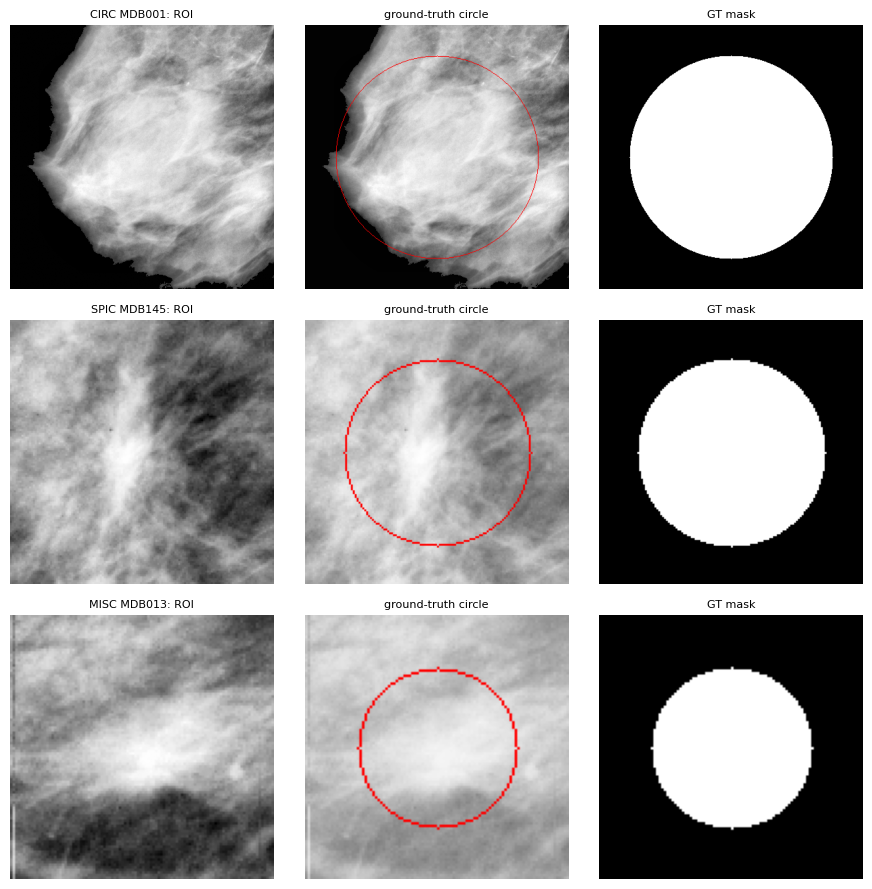

Saved to /content/drive/MyDrive/mias_grc_project_v3_cv


In [ ]:
np.savez_compressed(os.path.join(PREPROCESSED_DIR, "rois.npz"), **ROIS)
np.savez_compressed(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"), **GTS)
meta.to_csv(os.path.join(PREPROCESSED_DIR, "preprocessing_metadata.csv"), index=False)
final_df.to_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"), index=False)
json.dump({'n_folds': N_FOLDS, 'seed': SEED, 'folds': folds}, open(os.path.join(RESULTS_DIR, "folds.json"), 'w'))
json.dump(CONFIG, open(os.path.join(DRIVE_ROOT, "config.json"), 'w'), indent=2)

K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
picks = {c: final_df[final_df['class'] == c]['image_id'].iloc[0] for c in TARGET_CLASSES}
fig, ax = plt.subplots(len(picks), 3, figsize=(9, 3 * len(picks)))
for r, (c, i) in enumerate(picks.items()):
    gt = (GTS[i] > 127).astype(np.uint8); outline = gt ^ cv2.erode(gt, K3)
    ov = np.dstack([ROIS[i]] * 3); ov[outline == 1] = [1, 0, 0]
    ax[r, 0].imshow(ROIS[i], cmap='gray'); ax[r, 0].set_title(f"{c} {i}: ROI", fontsize=8)
    ax[r, 1].imshow(ov); ax[r, 1].set_title("ground-truth circle", fontsize=8)
    ax[r, 2].imshow(GTS[i], cmap='gray'); ax[r, 2].set_title("GT mask", fontsize=8)
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "mias_roi_gt_check.png"), dpi=130); plt.show()
print("Saved to", DRIVE_ROOT)

In [ ]:
def verify_mias1():
    f2 = json.load(open(os.path.join(RESULTS_DIR, "folds.json")))['folds']
    checks = {
        "mass images only (no NORM)"                     : set(final_df['class']) <= set(TARGET_CLASSES),
        "all images preprocessed"                        : len(ROIS) == len(final_df) == len(GTS),
        "ROI in [0,1]"                                   : all(v.min() >= 0 and v.max() <= 1 for v in ROIS.values()),
        "ROI and GT shapes agree"                        : all(ROIS[i].shape == GTS[i].shape for i in ROIS),
        "GT is non-empty and inside the ROI"             : all(0 < (GTS[i] > 0).mean() < 1 for i in GTS),
        "every image is a test image exactly once"       : sorted(sum([f['test_ids'] for f in f2], [])) == sorted(final_df['image_id']),
        "no patient in two parts of any fold"            : True,
        "validation subset is non-empty in every fold"   : all(len(f['val_ids']) >= 3 for f in f2),
        "outputs saved"                                  : all(os.path.exists(p) for p in [os.path.join(PREPROCESSED_DIR, "rois.npz"), os.path.join(PREPROCESSED_DIR, "gt_masks.npz"),
                                                                                           os.path.join(RESULTS_DIR, "final_df_loaded.csv"), os.path.join(RESULTS_DIR, "folds.json"), os.path.join(DRIVE_ROOT, "config.json")]),
    }
    print("=" * 56); print("MIAS NOTEBOOK 1 VERIFICATION"); print("=" * 56); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if v else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 56); print("Proceed to MIAS Notebook 2." if ok else "Fix failures first."); return ok
verify_mias1()

MIAS NOTEBOOK 1 VERIFICATION
  OK    mass images only (no NORM)
  OK    all images preprocessed
  OK    ROI in [0,1]
  OK    ROI and GT shapes agree
  OK    GT is non-empty and inside the ROI
  OK    every image is a test image exactly once
  OK    no patient in two parts of any fold
  OK    validation subset is non-empty in every fold
  OK    outputs saved
Proceed to MIAS Notebook 2.


True